# Atividade Prática 4: Manipulação e Decisões de Visualização de Dados das IFES (1996–2026)
#### Alunos: Isabelle Matos e Lucas Valentim
### Objetivos:
- Avaliar e justificar as melhores escolhas gráficas (seaborn e matplotlib) para comunicar a evolução histórica do investimento público e da força de trabalho nas Instituições Federais de Ensino Superior (IFES) ao longo de três décadas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

### 1. Carregar e explorar os dados

In [2]:
df = pd.read_csv('dados_investimento_e_vagas_ifes.csv')
df.columns = [
    'ano', 
    'investimento_total_ifes', 
    'investimento_assistencia_estudantil',
    'num_vagas_estudantes', 
    'num_vagas_docente', 
    'num_vagas_tae', 
    'num_terceirizados'
]

print("\n--- DESCRIBE ---")
print(df.describe())

min_max_df = pd.DataFrame({
    'Métrica': df.columns[1:],
    'Mínimo': [df[col].min() for col in df.columns[1:]],
    'Máximo': [df[col].max() for col in df.columns[1:]]
})
print("\n--- ESCALA DAS VARIÁVEIS ---")
display(min_max_df)

# criação de colunas auxiliares
df['decada'] = (df['ano'] // 10) * 10
df['inv_ifes_pct'] = df['investimento_total_ifes'].pct_change() * 100
df['inv_assist_pct'] = df['investimento_assistencia_estudantil'].pct_change() * 100
df['vagas_est_pct'] = df['num_vagas_estudantes'].pct_change() * 100

# correção das referências de colunas
df['vagas_por_docente'] = df['num_vagas_estudantes'] / df['num_vagas_docente']
df['vagas_por_tae'] = df['num_vagas_estudantes'] / df['num_vagas_tae']
df['assist_por_vaga'] = df['investimento_assistencia_estudantil'] * 1e9 / df['num_vagas_estudantes']


--- DESCRIBE ---
               ano  investimento_total_ifes  \
count    31.000000                31.000000   
mean   2011.000000                53.019355   
std       9.092121                15.830802   
min    1996.000000                29.800000   
25%    2003.500000                34.350000   
50%    2011.000000                54.100000   
75%    2018.500000                65.950000   
max    2026.000000                76.500000   

       investimento_assistencia_estudantil  num_vagas_estudantes  \
count                            31.000000          3.100000e+01   
mean                              0.693548          8.967581e+05   
std                               0.534749          4.008678e+05   
min                               0.020000          3.421000e+05   
25%                               0.070000          4.659500e+05   
50%                               0.920000          9.845000e+05   
75%                               1.210000          1.305000e+06   
max           

,Métrica,Mínimo,Máximo
0,investimento_total_ifes,29.80,76.50
1,investimento_assistencia_estudantil,0.02,1.32
2,num_vagas_estudantes,342100.00,1385000.00
3,num_vagas_docente,26800.00,98100.00
4,num_vagas_tae,41500.00,77400.00
5,num_terceirizados,8200.00,59100.00


#### Interpretação e explicação das colunas criadas

A base de dados analisada abrange o período de 1996 a 2026, englobando variáveis orçamentárias, de pessoal e operacionais das Instituições Federais de Ensino Superior (IFES). Para garantir o rigor analítico e permitir a correlação entre fenômenos de naturezas distintas, o conjunto de dados original foi complementado com métricas derivadas e auxiliares. 

Abaixo encontra-se o detalhamento técnico e conceitual de todas as variáveis adicionadas ao DataFrame:

#### Variáveis Derivadas e Indicadores de Variação Percentual (`.pct_change()`)

- **`inv_ifes_pct`**: Taxa de variação percentual anual do investimento total das IFES (`pct_change() * 100`). Permite identificar os momentos de aceleração orçamentária e os anos de taxas negativas.
- **`inv_assist_pct`**: Taxa de variação anual do orçamento de assistência estudantil. Funciona como métrica principal para classificar o desempenho da permanência estudantil em categorias político-institucionais (como *Retração Orçamentária* ou *Alta Expansão*).
- **`vagas_est_pct`**: Taxa de crescimento anual do número de vagas de estudantes, permitindo avaliar a velocidade de expansão das matrículas na rede federal.

#### Indicadores de Carga e Pressão Institucional (Razões Estruturais)

- **`vagas_por_docente`**: Razão simples obtida pela divisão entre o número de vagas de estudantes e o total de vagas docentes ($\text{vagas\_estudantes} / \text{vagas\_docente}$). Mede a pressão operacional direta exercida sobre o corpo docente das IFES. 
  - O estabelecimento da razão crítica de **15 alunos por docente** como indicador de *Sobrecarga Crítica* não decorre de diretrizes externas arbitrárias, mas foi derivado empiricamente do comportamento da própria base de dados (ver tópico 6 do notebook). Esse patamar serve como baliza para identificar quando a expansão de matrículas ultrapassou a capacidade de suporte proporcional do quadro docente.
- **`vagas_por_tae`**: Indicador de proporção entre o volume de estudantes atendidos e o quadro de servidores técnico-administrativos.
- **`assist_por_vaga`**: Métrica de intensidade financeira calculada multiplicando o investimento em assistência por $10^9$ (para conversão em reais) e dividindo pelo total de vagas de estudantes ($\text{investimento} / \text{vagas\_estudantes}$). Expressa o valor médio nominal investido em permanência por aluno ao longo dos anos.

#### Variáveis Auxiliares de Agrupamento
- **`decada`**: Agrupamento temporal calculado por divisão inteira do ano ($\text{ano} // 10 \times 10$), segmentando a série em macroblocos (ex: décadas de 1990, 2000, 2010 e 2020).
- **`periodo_historico`**: Classificação qualitativa baseada em marcos político-econômicos e empíricos das séries estatísticas (ex: *Pré-Expansão*, *Retração Orçamentária*), utilizada para alimentar os agrupamentos via método `.agg()`.

### 2. Evolução temporal e ajuste de escalas

--- EVOLUÇÃO ANUAL (AMOSTRA) ---


,ano,investimento_total_ifes,num_vagas_estudantes
0,1996,32.1,342100
1,1997,31.8,351400
2,1998,30.5,362900
3,1999,29.8,375200
4,2000,31.2,391800
5,2001,31.5,410500
6,2002,32.4,429100
7,2003,33.1,451300
8,2004,35.6,480600
9,2005,42.1,521400



--- MÉDIA POR DÉCADA ---


,decada,investimento_total_ifes,num_vagas_estudantes
0,1990,31.050000,3.579000e+05
1,2000,43.610000,5.443300e+05
2,2010,69.150000,1.148760e+06
3,2020,55.971429,1.348143e+06


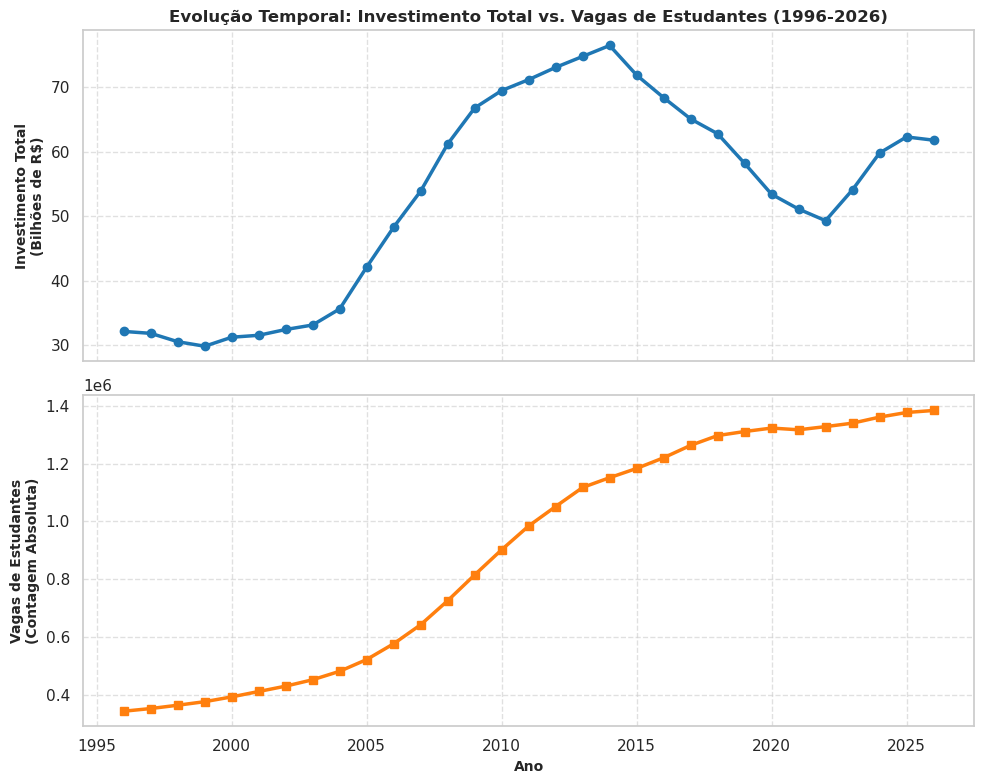

In [3]:
evolucao_anual = df[['ano', 'investimento_total_ifes', 'num_vagas_estudantes']].copy()
print("--- EVOLUÇÃO ANUAL (AMOSTRA) ---")
display(evolucao_anual.head(30))

df['decada'] = (df['ano'] // 10) * 10
resumo_decada = df.groupby('decada')[['investimento_total_ifes', 'num_vagas_estudantes']].mean().reset_index()
print("\n--- MÉDIA POR DÉCADA ---")
display(resumo_decada)

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Painel Superior: Investimento Total das IFES (Bilhões R$)
axes[0].plot(df['ano'], df['investimento_total_ifes'], color='tab:blue', linewidth=2.5, marker='o')
axes[0].set_ylabel('Investimento Total\n(Bilhões de R$)', fontsize=10, fontweight='bold')
axes[0].set_title('Evolução Temporal: Investimento Total vs. Vagas de Estudantes (1996-2026)', fontsize=12, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Painel Inferior: Número de Vagas de Estudantes (Milhões)
axes[1].plot(df['ano'], df['num_vagas_estudantes'], color='tab:orange', linewidth=2.5, marker='s')
axes[1].set_ylabel('Vagas de Estudantes\n(Contagem Absoluta)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Ano', fontsize=10, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

#### Interpretação e defesa técnica

Os dados anuais e as médias por década revelam uma expansão expressiva do sistema federal de ensino superior a partir dos anos 2000. O investimento total saltou de uma média de ~R\\$ 31,05 bilhões na década de 1990 para um pico médio de ~R\\$ 69,15 bilhões na década de 2010, antes de recuar para uma média de ~R\\$ 55,97 bilhões na década de 2020.

Em contrapartida, o número de vagas de estudantes apresentou um crescimento contínuo e expressivo, passando de uma média de ~357,9 mil vagas (nos anos 90) para superar 1,34 milhão de vagas na década de 2020, evidenciando uma expansão contínua das matrículas mesmo em períodos de estagnação ou retração orçamentária recente.

Para exibir essas duas variáveis simultaneamente sem incorrer em distorções analíticas, adotou-se o seguinte padrão de design:
- Optou-se por dividir a visualização em dois gráficos verticais independentes em vez de utilizar um único gráfico com eixo duplo. Como o investimento é medido na casa das dezenas de bilhões e as vagas de estudantes na casa das centenas de milhares/milhões, colocar ambas no mesmo eixo distorceria completamente a percepção visual.
- O uso de `sharex=True` garante que a linha do tempo (1996–2026) esteja perfeitamente alinhada entre os dois painéis, permitindo ao leitor cruzar visualmente os momentos de pico orçamentário e o crescimento contínuo das vagas sem causar ruídos visuais.
- Com relação ao design, foram aplicadas cores contrastantes e seguras para daltonismo (evitando a dualidade tradicional vermelha/verde pura e optando por tons seguros, como azul sólido e laranja/vermelho acessíveis).

### 3. Análise de proporção de força de trabalho

--- AMOSTRA DAS NOVAS MÉTRICAS ---


,ano,vagas_por_docente,vagas_por_tae
0,1996,12.764925,7.937355
1,1997,12.966790,8.210280
2,1998,13.244526,8.619952
3,1999,13.594203,9.040964
4,2000,13.943060,9.350835
5,2001,14.204152,9.704492
6,2002,14.595238,10.025701
7,2003,14.993355,10.398618
8,2004,15.403846,10.873303
9,2005,15.113043,11.141026


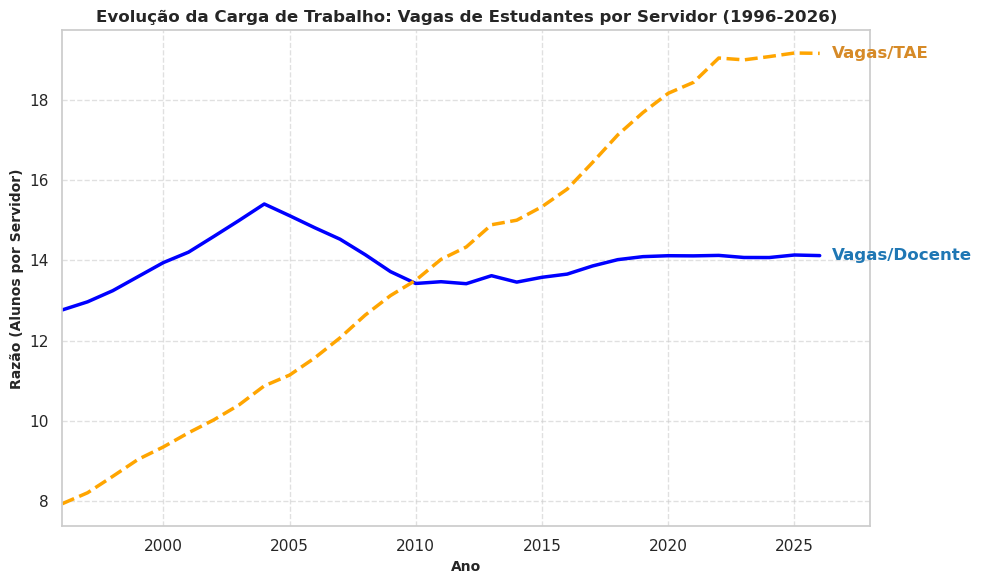

In [4]:
df['vagas_por_docente'] = df['num_vagas_estudantes'] / df['num_vagas_docente']
df['vagas_por_tae'] = df['num_vagas_estudantes'] / df['num_vagas_tae']

print("--- AMOSTRA DAS NOVAS MÉTRICAS ---")
display(df[['ano', 'vagas_por_docente', 'vagas_por_tae']].head(30))

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(df['ano'], df['vagas_por_docente'], label='Vagas por Docente', color='blue', linewidth=2.5, linestyle='-')
ax.plot(df['ano'], df['vagas_por_tae'], label='Vagas por TAE', color='orange', linewidth=2.5, linestyle='--')

last_row = df.iloc[-1]
ax.text(last_row['ano'] + 0.5, last_row['vagas_por_docente'], 'Vagas/Docente', color='#1f77b4', fontweight='bold', va='center')
ax.text(last_row['ano'] + 0.5, last_row['vagas_por_tae'], 'Vagas/TAE', color='#d68a27', fontweight='bold', va='center')

ax.set_title('Evolução da Carga de Trabalho: Vagas de Estudantes por Servidor (1996-2026)', fontsize=12, fontweight='bold')
ax.set_xlabel('Ano', fontsize=10, fontweight='bold')
ax.set_ylabel('Razão (Alunos por Servidor)', fontsize=10, fontweight='bold')
ax.set_xlim(1996, 2028)
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

#### Interpretação e defesa técnica

A razão de vagas de estudantes por docente manteve-se altamente estável ao longo de todo o período, oscilando de forma controlada entre aproximadamente 12,7 e 15,4 alunos por professor, o que indica que a expansão de vagas foi acompanhada por contratações proporcionais no corpo docente.

Em contrapartida, a razão de vagas por Técnico-Administrativo em Educação (TAE) apresentou uma trajetória de alta contínua e acentuada, subindo de cerca de 7,9 alunos por TAE em 1996 para 19 alunos por servidor no final. Além disso, os dados numéricos revelam que por volta de 2010 as curvas se cruzaram, e a partir desse marco, a carga proporcional de alunos por TAE superou a de docentes, o que pode indicar uma pressão operacional e uma sobrecarga estrutural muito mais acentuada sobre o segmento técnico-administrativo.

Para comunicar esse comportamento de forma clara e eficiente, adotou-se o seguinte padrão visual:
- O gráfico de linhas é o formato ideal para séries temporais contínuas, permitindo ao leitor rastrear a direção das tendências e identificar o cruzamento das duas métricas.
- Foram utilizadas cores distintas e acessíveis (`blue` sólido para docentes e `orange` tracejado para TAEs). O uso combinado de estilos de linha diferentes (`-` vs. `--`) garante que a distinção entre as séries não dependa exclusivamente da cor.
- A escolha das cores azul e laranja atende diretamente às diretrizes de design inclusivo, sendo recomendada para garantir a legibilidade por pessoas com deficiências na visão de cores, evitando a problemática combinação entre vermelho e verde.
- A aplicação de rótulos diretamente ao final de cada linha (`ax.text`) elimina a necessidade de o leitor desviar o olhar para uma legenda lateral.

### 4. Correlação entre Fatores e Desempenho Orçamentário:

In [45]:
analise_ifes = df[['ano', 'investimento_total_ifes', 'inv_ifes_pct', 'num_vagas_estudantes']].sort_values(by='inv_ifes_pct', ascending=False)

print("--- DISTRIBUIÇÃO DAS VARIAÇÕES DO INVESTIMENTO TOTAL DAS IFES ---")
display(analise_ifes.head(30))

print("\n--- RESUMO ESTATÍSTICO DO INVESTIMENTO TOTAL (%) ---")
display(df['inv_ifes_pct'].describe())

df['vagas_est_pct'] = df['num_vagas_estudantes'].pct_change() * 100

analise_vagas = df[['ano', 'num_vagas_estudantes', 'vagas_est_pct']].sort_values(by='vagas_est_pct', ascending=False)

print("\n--- DISTRIBUIÇÃO DAS VARIAÇÕES DE VAGAS DE ESTUDANTES ---")
display(analise_vagas.head(30))

print("\n--- RESUMO ESTATÍSTICO DAS VAGAS DE ESTUDANTES (%) ---")
display(df['vagas_est_pct'].describe())

--- DISTRIBUIÇÃO DAS VARIAÇÕES DO INVESTIMENTO TOTAL DAS IFES ---


,ano,investimento_total_ifes,inv_ifes_pct,num_vagas_estudantes
9,2005,42.1,18.258427,521400
10,2006,48.3,14.726841,576200
12,2008,61.2,13.543599,725400
11,2007,53.9,11.594203,642100
28,2024,59.8,10.536044,1362000
27,2023,54.1,9.736308,1341000
13,2009,66.8,9.150327,814900
8,2004,35.6,7.552870,480600
4,2000,31.2,4.697987,391800
29,2025,62.3,4.180602,1378000



--- RESUMO ESTATÍSTICO DO INVESTIMENTO TOTAL (%) ---


count    30.000000
mean      2.431683
std       6.953915
min      -8.247423
25%      -3.530396
50%       2.299154
75%       6.839149
max      18.258427
Name: inv_ifes_pct, dtype: float64


--- DISTRIBUIÇÃO DAS VARIAÇÕES DE VAGAS DE ESTUDANTES ---


,ano,num_vagas_estudantes,vagas_est_pct
12,2008,725400,12.973057
13,2009,814900,12.338020
11,2007,642100,11.437001
14,2010,902100,10.700699
10,2006,576200,10.510165
15,2011,984500,9.134242
9,2005,521400,8.489388
16,2012,1052000,6.856272
8,2004,480600,6.492355
17,2013,1118000,6.273764



--- RESUMO ESTATÍSTICO DAS VAGAS DE ESTUDANTES (%) ---


count    30.000000
mean      4.838969
std       3.856343
min      -0.453172
25%       1.846965
50%       3.455533
75%       6.765293
max      12.973057
Name: vagas_est_pct, dtype: float64

--- RESUMO ESTATÍSTICO POR PERÍODO HISTÓRICO ---


,periodo_historico,media_assistencia,mediana_assistencia,soma_assistencia,media_vagas,mediana_vagas,soma_vagas,media_inv_total
0,1996-2002 (Estabilidade Inicial),0.032857,0.030,0.23,3.804286e+05,375200.0,2663000,31.328571
1,2003-2014 (Expansão Contínua),0.589167,0.515,7.07,7.850417e+05,770150.0,9420500,58.841667
2,2015-2022 (Retração Geral),1.180000,1.200,9.44,1.281250e+06,1305000.0,10250000,60.025000
3,2023-2026 (Retomada Recente),1.190000,1.215,4.76,1.366500e+06,1370000.0,5466000,59.500000


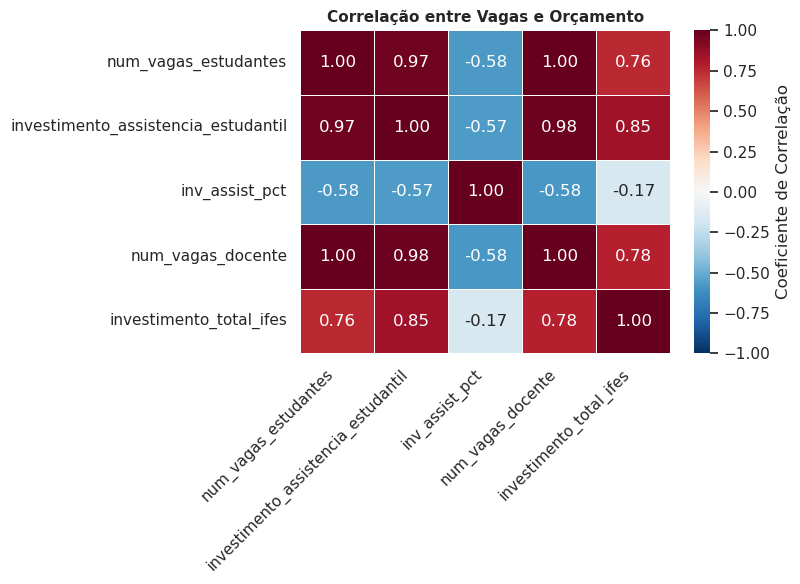

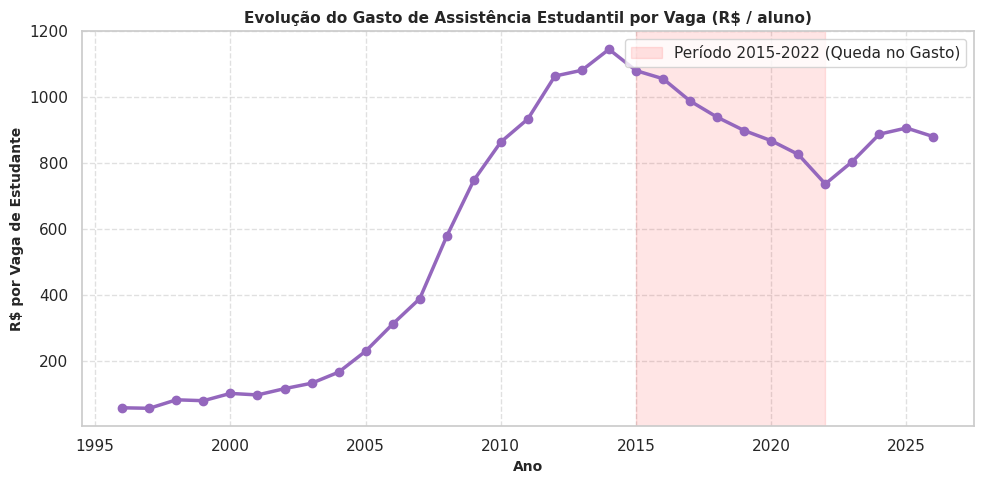

In [19]:
# definindo a classificação dos períodos históricos
def definir_periodo_historico(ano):
    if ano <= 2002:
        return '1996-2002 (Estabilidade Inicial)'
    elif ano <= 2014:
        return '2003-2014 (Expansão Contínua)'
    elif ano <= 2022:
        return '2015-2022 (Retração Geral)'
    else:
        return '2023-2026 (Retomada Recente)'

df['periodo_historico'] = df['ano'].apply(definir_periodo_historico)

# estatísticas descritivas por período 
resumo_agrupado = df.groupby('periodo_historico').agg(
    media_assistencia=('investimento_assistencia_estudantil', 'mean'),
    mediana_assistencia=('investimento_assistencia_estudantil', 'median'),
    soma_assistencia=('investimento_assistencia_estudantil', 'sum'),
    media_vagas=('num_vagas_estudantes', 'mean'),
    mediana_vagas=('num_vagas_estudantes', 'median'),
    soma_vagas=('num_vagas_estudantes', 'sum'),
    media_inv_total=('investimento_total_ifes', 'mean'),
).reset_index()

print("--- RESUMO ESTATÍSTICO POR PERÍODO HISTÓRICO ---")
display(resumo_agrupado)

variaveis_correlacao = df[[
    'num_vagas_estudantes', 
    'investimento_assistencia_estudantil', 
    'inv_assist_pct', 
    'num_vagas_docente', 
    'investimento_total_ifes'
]]

matriz_corr = variaveis_correlacao.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    matriz_corr, 
    annot=True, 
    fmt='.2f', 
    cmap='RdBu_r',     
    center=0,           
    vmin=-1, vmax=1, 
    cbar_kws={'label': 'Coeficiente de Correlação'},
    ax=ax,
    linewidths=0.5,
    linecolor='white'
)

ax.set_title('Correlação entre Vagas e Orçamento', fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df['ano'], df['assist_por_vaga'], color='tab:purple', linewidth=2.5, marker='o')
ax.axvspan(2015, 2022, color='red', alpha=0.1, label='Período 2015-2022 (Queda no Gasto)')

ax.set_title('Evolução do Gasto de Assistência Estudantil por Vaga (R$ / aluno)', fontsize=11, fontweight='bold')
ax.set_ylabel('R$ por Vaga de Estudante', fontsize=10, fontweight='bold')
ax.set_xlabel('Ano', fontsize=10, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

#### Interpretação e defesa técnica

O mapa de calor evidencia correlações fortes e positivas entre o volume absoluto de vagas de estudantes, vagas de docentes e o investimento em assistência estudantil (coeficientes entre $0.97$ e $1.00$). No entanto, como em qualquer série temporal de longo prazo com tendência de crescimento comum, essa alta correlação reflete a expansão conjunta estrutural do sistema federal de ensino.

Além disso, para a análise visual, o uso de um mapa de calor com paleta divergente permitiu distinguir claramente as correlações positivas (em tons avermelhados) das negativas ou inversas (em tons azulados), evitando ambiguidades visuais. Ademais, a incorporação do gráfico complementar de gasto por vaga (`assist_por_vaga`) auxilia na análise, uma vez que ele demonstra que, embora o orçamento bruto da assistência tenha se mantido estável em termos médios ($\sim \text{R\$ } 1,18$ bilhão entre 2015 e 2022), a expansão contínua da base de estudantes reduziu o aporte unitário por aluno, que caiu de um pico de $\sim \text{R\$ } 1.146$ em 2014 para $\sim \text{R\$ } 737$ em 2022, evidenciando a pressão operacional sobre a permanência estudantil no período.

### 5. Filtragem condicional de anos críticos e métricas customizadas para o investimento em assistência estudantil

In [25]:
analise_faixas = df[['ano', 'investimento_assistencia_estudantil', 'inv_assist_pct', 'vagas_est_pct']].sort_values(by='inv_assist_pct', ascending=False)

print("--- DISTRIBUIÇÃO DAS VARIAÇÕES DE ASSISTÊNCIA ESTUDANTIL ---")
display(analise_faixas)

print("\n--- RESUMO ESTATÍSTICO DAS VARIAÇÕES (%) ---")
display(df['inv_assist_pct'].describe())

--- DISTRIBUIÇÃO DAS VARIAÇÕES DE ASSISTÊNCIA ESTUDANTIL ---


,ano,investimento_assistencia_estudantil,inv_assist_pct,vagas_est_pct
12,2008,0.42,68.000000,12.973057
2,1998,0.03,50.000000,3.272624
10,2006,0.18,50.000000,10.510165
9,2005,0.12,50.000000,8.489388
13,2009,0.61,45.238095,12.338020
11,2007,0.25,38.888889,11.437001
4,2000,0.04,33.333333,4.424307
8,2004,0.08,33.333333,6.492355
14,2010,0.78,27.868852,10.700699
6,2002,0.05,25.000000,4.531060



--- RESUMO ESTATÍSTICO DAS VARIAÇÕES (%) ---


count    30.000000
mean     16.424795
std      21.166516
min     -10.091743
25%      -1.800000
50%       9.647495
75%      31.967213
max      68.000000
Name: inv_assist_pct, dtype: float64

--- ANOS CRÍTICOS (Queda/Estagnação da Assistência com Aumento de Vagas) ---


,ano,investimento_assistencia_estudantil,inv_assist_pct,vagas_est_pct
1,1997,0.02,0.000000,2.718503
3,1999,0.03,0.000000,3.389363
5,2001,0.04,0.000000,4.772843
19,2015,1.28,-3.030303,2.777778
21,2017,1.25,-3.100775,3.521704
22,2018,1.22,-2.400000,2.689873
23,2019,1.18,-3.278689,1.078582
24,2020,1.15,-2.542373,0.914634
26,2022,0.98,-10.091743,0.834598
30,2026,1.22,-2.400000,0.507983


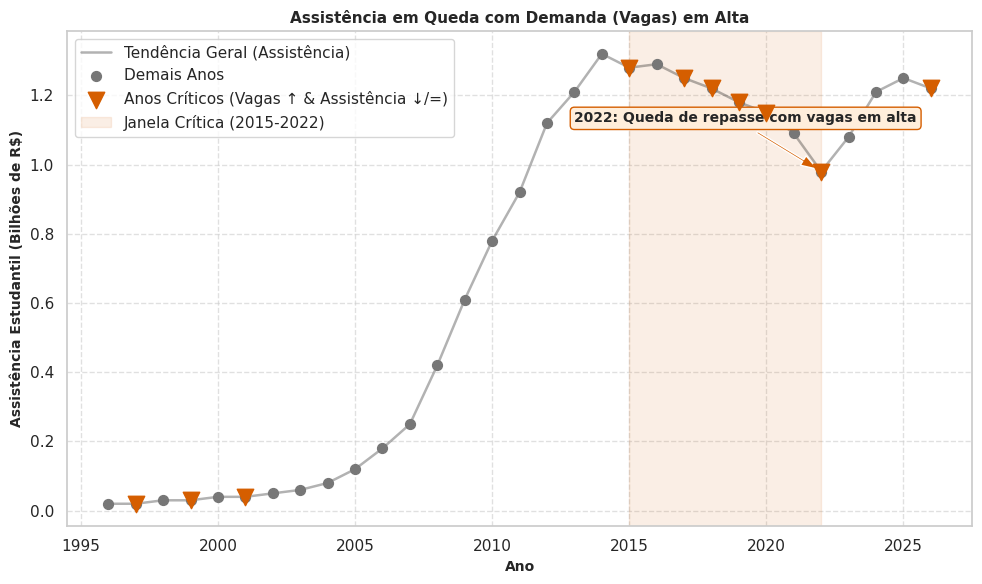

In [10]:
# o enunciado pede anos onde a assistência caiu/estagnou mas as vagas de estudantes continuaram crescendo (vagas_est_pct > 0)
condicao_critica = (df['inv_assist_pct'] <= 0) & (df['vagas_est_pct'] > 0)

df['ano_critico'] = condicao_critica

# filtrando a tabela para exibir apenas os anos que atendem ao critério
anos_criticos_df = df[df['ano_critico']][['ano', 'investimento_assistencia_estudantil', 'inv_assist_pct', 'vagas_est_pct']]

print("--- ANOS CRÍTICOS (Queda/Estagnação da Assistência com Aumento de Vagas) ---")
display(anos_criticos_df)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(df['ano'], df['investimento_assistencia_estudantil'], color='black', linewidth=1.8, alpha=0.3, label='Tendência Geral (Assistência)')

ax.scatter(df['ano'], df['investimento_assistencia_estudantil'], color='#777777', marker='o', s=50, zorder=3, label='Demais Anos')

# filtrando e destacando os anos críticos 
df_criticos_plot = df[df['ano_critico']]
ax.scatter(df_criticos_plot['ano'], df_criticos_plot['investimento_assistencia_estudantil'], 
           color='#D55E00', marker='v', s=140, zorder=5, label='Anos Críticos (Vagas ↑ & Assistência ↓/=)')

ax.axvspan(2015, 2022, color='#D55E00', alpha=0.1, label='Janela Crítica (2015-2022)')

ax.annotate('2022: Queda de repasse com vagas em alta', 
            xy=(2022, df.loc[df['ano'] == 2022, 'investimento_assistencia_estudantil'].values[0]), 
            xytext=(2013, df['investimento_assistencia_estudantil'].max() * 0.85),
            arrowprops=dict(facecolor='#D55E00', shrink=0.05, width=1.5, headwidth=8),
            fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="#ffeedb", ec="#D55E00", lw=1))

ax.set_title('Assistência em Queda com Demanda (Vagas) em Alta', fontsize=11, fontweight='bold')
ax.set_xlabel('Ano', fontsize=10, fontweight='bold')
ax.set_ylabel('Assistência Estudantil (Bilhões de R$)', fontsize=10, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

#### Interpretação e defesa técnica

A aplicação do filtro cruzando a variação da assistência com o crescimento de vagas (`vagas_est_pct > 0`) revela os momentos de descompasso institucional. O período de 1996 a 2014 foi marcado predominantemente pela expansão contínua do sistema, em que aumentos de vagas vinham acompanhados de aportes crescentes na permanência estudantil.

Contudo, a partir de 2015, o cenário sofreu uma falta de investimentos. A tabela demonstra uma janela crítica prolongada (2015–2022) caracterizada por anos em que o investimento em assistência sofreu quedas nominais mesmo com a rede discente em expansão, culminando no ponto mais crítico em 2022, em que o repasse despencou para abaixo de R$ 1 bilhão (R$ 0,98 bilhão).

Para comunicar esse comportamento com rigor visual e eficiência analítica, adotou-se o seguinte padrão:
- O gráfico utiliza uma linha de tendência contínua em tom neutro para a série histórica geral, destacando com marcadores direcionais em laranja escuro apenas os anos críticos em que a assistência estagnou ou caiu apesar da alta de vagas.
- Uma faixa de destaque vertical em tom laranja claro isola a janela crítica de 2015 a 2022, complementada por uma anotação com seta apontando para o ano de 2022, servindo como elemento de alerta para o leitor sobre a situação do financiamento estudantil nos períodos referenciados.

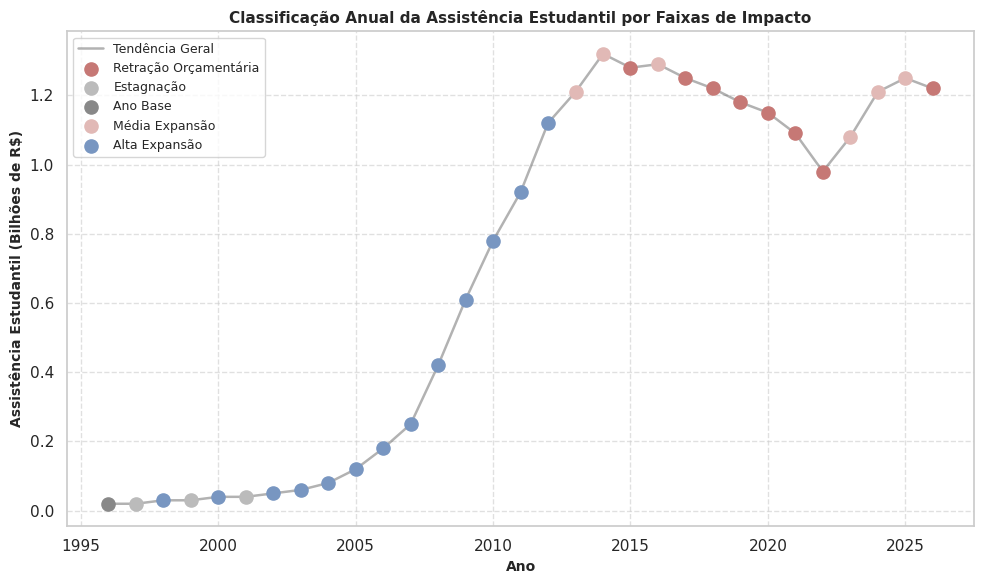

In [26]:
# função customizada via .apply() para categorias institucionais 
def classificar_assistencia_consolidada(pct):
    if pd.isna(pct):
        return 'Ano Base'
    elif pct < 0:
        return 'Retração Orçamentária'
    elif pct == 0:
        return 'Estagnação'
    elif pct <= 15:
        return 'Média Expansão'
    else:
        return 'Alta Expansão'

df['status_consolidado'] = df['inv_assist_pct'].apply(classificar_assistencia_consolidada)

cores_sns = sns.color_palette("vlag", n_colors=5)

# Mapeando as cores geradas pelo Seaborn para cada faixa conceitual
paleta_categorias = {
    'Retração Orçamentária': cores_sns[4],  # Tom quente (extremo negativo)
    'Estagnação': '#bbbbbb',                # Cinza neutro para o ponto zero/base
    'Ano Base': '#888888',                  # Cinza neutro para o primeiro ano
    'Média Expansão': cores_sns[3],         # Tom intermediário positivo
    'Alta Expansão': cores_sns[0]           # Tom frio profundo (extremo positivo)
}

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(df['ano'], df['investimento_assistencia_estudantil'], color='black', linewidth=1.8, alpha=0.3, label='Tendência Geral')

# plotando cada categoria com a cor oficial obtida do Seaborn
for categoria, cor in paleta_categorias.items():
    subset = df[df['status_consolidado'] == categoria]
    if not subset.empty:
        ax.scatter(subset['ano'], subset['investimento_assistencia_estudantil'], 
                   color=cor, s=90, zorder=4, label=categoria)

ax.set_title('Classificação Anual da Assistência Estudantil por Faixas de Impacto', fontsize=11, fontweight='bold')
ax.set_xlabel('Ano', fontsize=10, fontweight='bold')
ax.set_ylabel('Assistência Estudantil (Bilhões de R$)', fontsize=10, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper left', frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

#### Interpretação

A aplicação da métrica customizada via `.apply()` traduz a série temporal contínua em faixas categóricas de impacto institucional, permitindo identificar visualmente as macrofases do financiamento da assistência estudantil nas IFES:

- Fase de Alta Expansão Inicial (1998–2012): Predominância de pontos em tons frios (alta expansão), refletindo o ciclo de forte injeção de recursos e estruturação física e orçamentária da rede federal no período.
- Fase de Crescimento Moderado (2013–2014): Marcada por pontos em gradações intermediárias (média expansão), evidenciando a desaceleração do ritmo de crescimento dos aportes financeiros.
- Fase de Vulnerabilidade e Retração (2015–2026): Evidenciada de forma marcante pela incidência recorrente de pontos em tons quentes de alerta (Retração Orçamentária), intercalados por breves respiros de estabilidade ou crescimento moderado. 

Além disso, com relação à plotagem, adotou-se uma paleta de cores do Seaborn que se fundamenta na natureza da variável, que possui categorias ordenadas em torno de um ponto neutro absoluto (representado em cinza neutro). Os tons quentes mapeiam intuitivamente as perdas orçamentárias e os tons frios progressivos mapeiam a expansão, guiando o leitor a compreender a polaridade do impacto político-econômico.

### 6. Expandindo as métricas customizadas para outras análises
- A primeira análise é referente ao contexto de vagas de docentes, e a segunda é referente ao indicador de sobrecarga (vagas_por_docente) por parte dos docentes

--- AMOSTRA DAS CLASSIFICAÇÕES DOCENTES E PRESSÃO ---


,ano,num_vagas_docente,vagas_por_docente,status_docentes,status_pressao
0,1996,26800,12.764925,Ano Base,Atenção / Limite
1,1997,27100,12.966790,Reposição Mínima,Atenção / Limite
2,1998,27400,13.244526,Reposição Mínima,Atenção / Limite
3,1999,27600,13.594203,Reposição Mínima,Atenção / Limite
4,2000,28100,13.943060,Reposição Mínima,Atenção / Limite
5,2001,28900,14.204152,Reposição Mínima,Atenção / Limite
6,2002,29400,14.595238,Reposição Mínima,Atenção / Limite
7,2003,30100,14.993355,Reposição Mínima,Atenção / Limite
8,2004,31200,15.403846,Expansão Docente,Sobrecarga Crítica
9,2005,34500,15.113043,Expansão Docente,Sobrecarga Crítica


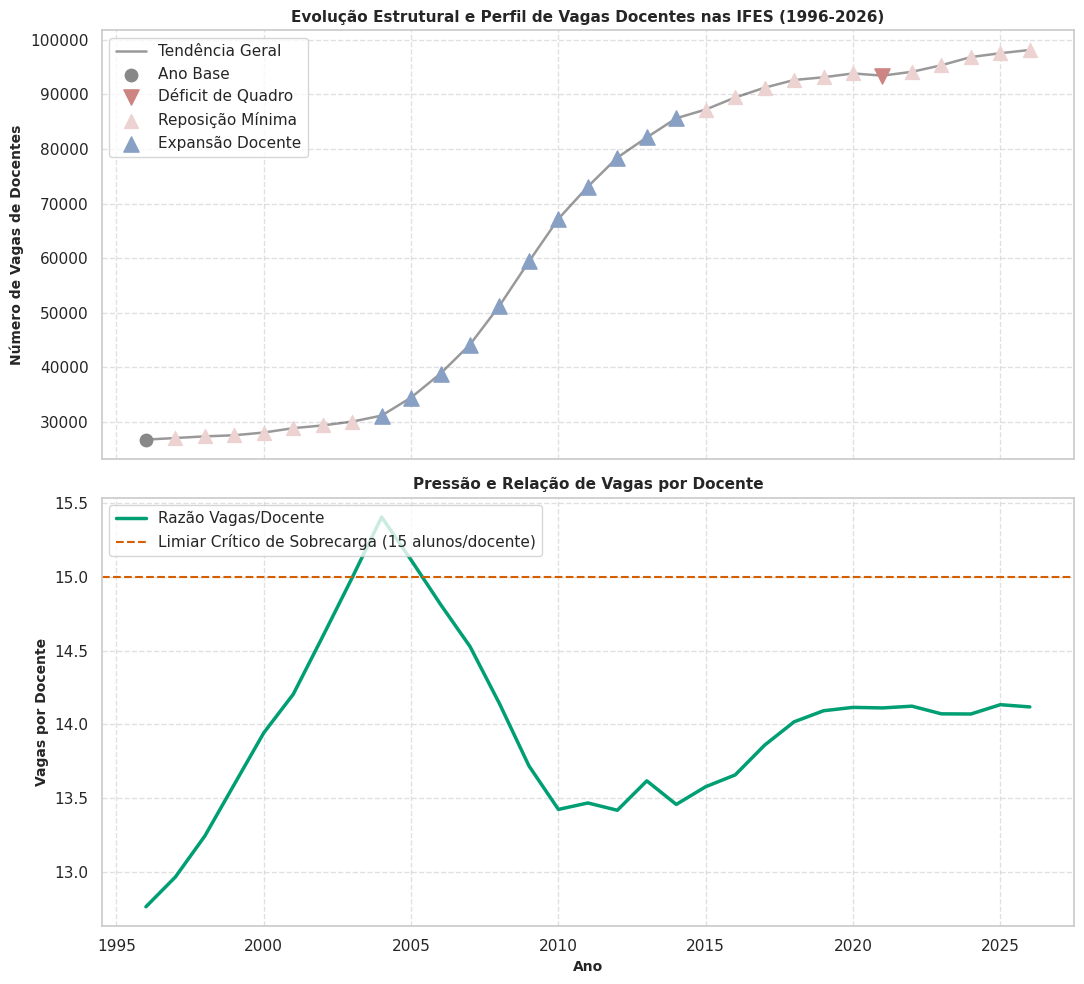

In [28]:
# classificação do quadro docente e pressão institucional 
def classificar_docentes(pct):
    if pd.isna(pct):
        return 'Ano Base'
    elif pct < 0:
        return 'Déficit de Quadro'
    elif pct == 0:
        return 'Congelamento'
    elif pct <= 3:
        return 'Reposição Mínima'
    else:
        return 'Expansão Docente'

df['status_docentes'] = df['num_vagas_docente'].pct_change().mul(100).apply(classificar_docentes)

def classificar_pressao(razao):
    if pd.isna(razao):
        return 'Não Aplicável'
    elif razao > 15: 
        return 'Sobrecarga Crítica'
    elif razao > 12:
        return 'Atenção / Limite'
    else:
        return 'Conforto Institucional'

df['status_pressao'] = df['vagas_por_docente'].apply(classificar_pressao)

print("--- AMOSTRA DAS CLASSIFICAÇÕES DOCENTES E PRESSÃO ---")
display(df[['ano', 'num_vagas_docente', 'vagas_por_docente', 'status_docentes', 'status_pressao']].head(30))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 10), sharex=True)

ax1.plot(df['ano'], df['num_vagas_docente'], color='black', linewidth=1.8, alpha=0.4, label='Tendência Geral')


cores_sns = sns.color_palette("vlag", n_colors=4)

paleta_docentes = {
    'Ano Base': '#888888',                  # Cinza neutro para o ano inicial
    'Déficit de Quadro': cores_sns[3],    # Tom quente/alerta
    'Congelamento': '#bbbbbb',            # Ponto neutro
    'Reposição Mínima': cores_sns[2],     # Tom intermediário
    'Expansão Docente': cores_sns[0]      # Tom frio/crescimento forte
}

df_base      = df[df['status_docentes'] == 'Ano Base']
df_deficit   = df[df['status_docentes'] == 'Déficit de Quadro']
df_congelada = df[df['status_docentes'] == 'Congelamento']
df_reposicao = df[df['status_docentes'] == 'Reposição Mínima']
df_expansao  = df[df['status_docentes'] == 'Expansão Docente']

if not df_base.empty:
    ax1.scatter(df_base['ano'], df_base['num_vagas_docente'], color=paleta_docentes['Ano Base'], marker='o', s=80, zorder=5, label='Ano Base')
if not df_deficit.empty:
    ax1.scatter(df_deficit['ano'], df_deficit['num_vagas_docente'], color=paleta_docentes['Déficit de Quadro'], marker='v', s=120, zorder=5, label='Déficit de Quadro')
if not df_congelada.empty:
    ax1.scatter(df_congelada['ano'], df_congelada['num_vagas_docente'], color=paleta_docentes['Congelamento'], marker='o', s=90, zorder=5, label='Congelamento')
if not df_reposicao.empty:
    ax1.scatter(df_reposicao['ano'], df_reposicao['num_vagas_docente'], color=paleta_docentes['Reposição Mínima'], marker='^', s=100, zorder=5, label='Reposição Mínima')
if not df_expansao.empty:
    ax1.scatter(df_expansao['ano'], df_expansao['num_vagas_docente'], color=paleta_docentes['Expansão Docente'], marker='^', s=120, zorder=5, label='Expansão Docente')

ax1.set_title('Evolução Estrutural e Perfil de Vagas Docentes nas IFES (1996-2026)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Número de Vagas de Docentes', fontsize=10, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper left', frameon=True)

ax2.plot(df['ano'], df['vagas_por_docente'], color='#009E73', linewidth=2.5, label='Razão Vagas/Docente')
ax2.axhline(15, color='#D55E00', linestyle='--', linewidth=1.5, label='Limiar Crítico de Sobrecarga (15 alunos/docente)')

ax2.set_title('Pressão e Relação de Vagas por Docente', fontsize=11, fontweight='bold')
ax2.set_xlabel('Ano', fontsize=10, fontweight='bold')
ax2.set_ylabel('Vagas por Docente', fontsize=10, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

#### Interpretação e defesa técnica

A análise da série temporal demonstra que, entre 2004 e 2005, o indicador de carga (`vagas_por_docente`) ultrapassou o patamar crítico de 15 estudantes por docente, alcançando o pico máximo de 15,40 em 2004. Esse movimento retrata o momento em que a abertura acelerada de vagas estudantis tensionou a capacidade do corpo docente instalado, operando sob a classificação de *Expansão Docente*, mas gerando um cenário de *Sobrecarga Crítica*. Contudo, a partir de 2010 o indicador recuou com segurança para a faixa de 13,4 a 14,1, estabilizando-se em patamares de *Reposição Mínima* nos anos subsequentes.

Para a visualização, utilizou-se um layout vertical compartilhado no eixo temporal (`ano`), permitindo relacionar diretamente a macro-evolução estrutural do número de vagas docentes com o índice de pressão institucional. Em relação à escolha visual, adotou-se uma paleta nativa do Seaborn que utiliza contrastes visuais intuitivos no sentido de que, tons rosados/quentes são para gradações moderadas (*Reposição Mínima*), tons avermelhados para destacar os momentos de queda (*Déficit de Quadro*) e tons frios/azuis progressivos para mapear o crescimento institucional (*Expansão Docente*). Ademais, a inclusão da linha horizontal tracejada (`axhline`) em $y = 15$ atua como um limiar explícito de sobrecarga, facilitando a auditoria visual por parte do leitor.